In [41]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!find "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/moved" -type f -name "*.json" | wc -l

10920


In [5]:
import glob
import json
import pandas as pd
import os

def load_hansard_jsons_to_df(input_dir):
    rows = []

    files = sorted(glob.glob(os.path.join(input_dir, "*.json")))

    for path in files:
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        data["_filename"] = os.path.basename(path)
        data["_path"] = path
        rows.append(data)

    df = pd.DataFrame(rows)
    return df


In [4]:
df = load_hansard_jsons_to_df(input_dir="/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/moved")

In [5]:
df.head()

,HpsProceedingHeading,HpsProceedingContent,classification_label,classification_confidence,classification_reason,_filename,_path
0,"Tuesday, 7 February 2012",Mr Speaker took the Chair at 2 p.m.\n\nPrayers.,irrelevant,1.00,The document section describes parliamentary p...,hansard_2012-02-07_body_section_0.json,/content/drive/MyDrive/NZ/University of Waikat...
1,Members Sworn,"Charles Chauvel, Hon Annette King, and Hon Mar...",irrelevant,0.95,The document section describes a standard parl...,hansard_2012-02-07_body_section_1.json,/content/drive/MyDrive/NZ/University of Waikat...
2,Sweden—Committee on Environment and Agricultur...,Mr SPEAKER : I have much pleasure in informing...,non_maori_origin,0.95,The document section describes the Speaker wel...,hansard_2012-02-07_body_section_2.json,/content/drive/MyDrive/NZ/University of Waikat...
3,Queen Elizabeth II—Diamond Jubilee,Rt Hon JOHN KEY (Prime Minister): I seek leave...,maori_origin,0.90,While the primary topic is the Queen's Diamond...,hansard_2012-02-07_body_section_3.json,/content/drive/MyDrive/NZ/University of Waikat...
4,Questions to Ministers,Economy—Government Priorities and Challenges\n...,maori_origin,0.95,The document contains multiple substantive dis...,hansard_2012-02-07_body_section_4.json,/content/drive/MyDrive/NZ/University of Waikat...


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10920 entries, 0 to 10919
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   HpsProceedingHeading       10920 non-null  object 
 1   HpsProceedingContent       10920 non-null  object 
 2   classification_label       10920 non-null  object 
 3   classification_confidence  10920 non-null  float64
 4   classification_reason      10920 non-null  object 
 5   _filename                  10920 non-null  object 
 6   _path                      10920 non-null  object 
dtypes: float64(1), object(6)
memory usage: 597.3+ KB


In [7]:
df.to_parquet("hansard.parquet")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10920 entries, 0 to 10919
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   HpsProceedingHeading       10920 non-null  object 
 1   HpsProceedingContent       10920 non-null  object 
 2   classification_label       10920 non-null  object 
 3   classification_confidence  10920 non-null  float64
 4   classification_reason      10920 non-null  object 
 5   _filename                  10920 non-null  object 
 6   _path                      10920 non-null  object 
dtypes: float64(1), object(6)
memory usage: 597.3+ KB


In [34]:
# !cp "hansard.parquet" "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/hansard_classified.parquet"

In [3]:
!cp "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/hansard_classified.parquet" "hansard.parquet"

In [9]:
df = pd.read_parquet("hansard.parquet")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10920 entries, 0 to 10919
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   HpsProceedingHeading       10920 non-null  object 
 1   HpsProceedingContent       10920 non-null  object 
 2   classification_label       10920 non-null  object 
 3   classification_confidence  10920 non-null  float64
 4   classification_reason      10920 non-null  object 
 5   _filename                  10920 non-null  object 
 6   _path                      10920 non-null  object 
dtypes: float64(1), object(6)
memory usage: 597.3+ KB


In [10]:
import os

def inspect_file_size(file_path: str):
    size_bytes = os.path.getsize(file_path)
    print(f"{size_bytes / (1024**2):.2f} MB")

inspect_file_size("hansard.parquet")

187.48 MB


## EDA

### 1️⃣Counts of classification_label

In [11]:
df["classification_label"].value_counts()

,count
classification_label,
non_maori_origin,5532
maori_origin,3417
irrelevant,1971


In [12]:
label_counts = (
    df["classification_label"]
    .value_counts()
    .to_frame("count")
)

label_counts["percent"] = (
    label_counts["count"] / label_counts["count"].sum() * 100
)

label_counts


,count,percent
classification_label,,
non_maori_origin,5532,50.659341
maori_origin,3417,31.291209
irrelevant,1971,18.049451


In [13]:
import matplotlib.pyplot as plt

def plot_label_counts(input_df):
  label_counts = (
      input_df["classification_label"]
      .value_counts()
      .to_frame("count")
  )

  label_counts["percent"] = (
      label_counts["count"] / label_counts["count"].sum() * 100
  )
  ax = label_counts["count"].plot(kind="bar", title="Classification Label Counts")

  # Add raw count labels on top of the bars
  for container in ax.containers:
      ax.bar_label(container, fmt='%d')

  plt.ylabel("Count")
  plt.xticks(rotation=45, ha='right')
  plt.tight_layout()

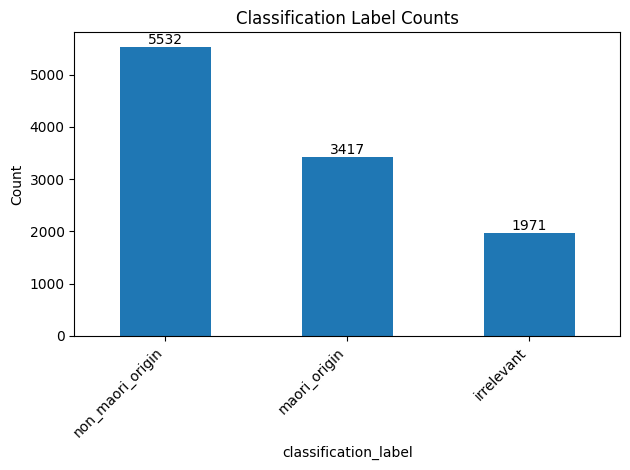

In [14]:
plot_label_counts(df)

#### Remove Irrelevant Ones

In [15]:
df_filtered = df[df["classification_label"] != "irrelevant"].copy()

In [16]:
print("Current index of df_filtered:")
print(df_filtered.index)

# Display the head to show the current index
display(df_filtered.head())

Current index of df_filtered:
Index([    2,     3,     4,     5,     6,     7,     8,     9,    12,    13,
       ...
       10908, 10909, 10910, 10911, 10914, 10915, 10916, 10917, 10918, 10919],
      dtype='int64', length=8949)


,HpsProceedingHeading,HpsProceedingContent,classification_label,classification_confidence,classification_reason,_filename,_path
2,Sweden—Committee on Environment and Agricultur...,Mr SPEAKER : I have much pleasure in informing...,non_maori_origin,0.95,The document section describes the Speaker wel...,hansard_2012-02-07_body_section_2.json,/content/drive/MyDrive/NZ/University of Waikat...
3,Queen Elizabeth II—Diamond Jubilee,Rt Hon JOHN KEY (Prime Minister): I seek leave...,maori_origin,0.90,While the primary topic is the Queen's Diamond...,hansard_2012-02-07_body_section_3.json,/content/drive/MyDrive/NZ/University of Waikat...
4,Questions to Ministers,Economy—Government Priorities and Challenges\n...,maori_origin,0.95,The document contains multiple substantive dis...,hansard_2012-02-07_body_section_4.json,/content/drive/MyDrive/NZ/University of Waikat...
5,Address in Reply,Debate resumed from 21 December 2011.\n\nHon G...,maori_origin,0.90,The document contains substantive discussion o...,hansard_2012-02-07_body_section_5.json,/content/drive/MyDrive/NZ/University of Waikat...
6,National Animal Identification and Tracing Bill,In Committee\n\nHon DAVID CARTER (Minister for...,non_maori_origin,1.00,The document contains a substantive parliament...,hansard_2012-02-07_body_section_6.json,/content/drive/MyDrive/NZ/University of Waikat...


In [17]:
df_filtered = df_filtered.reset_index(drop=True)
print("Index after resetting:")
print(df_filtered.index)
display(df_filtered.head())

Index after resetting:
RangeIndex(start=0, stop=8949, step=1)


,HpsProceedingHeading,HpsProceedingContent,classification_label,classification_confidence,classification_reason,_filename,_path
0,Sweden—Committee on Environment and Agricultur...,Mr SPEAKER : I have much pleasure in informing...,non_maori_origin,0.95,The document section describes the Speaker wel...,hansard_2012-02-07_body_section_2.json,/content/drive/MyDrive/NZ/University of Waikat...
1,Queen Elizabeth II—Diamond Jubilee,Rt Hon JOHN KEY (Prime Minister): I seek leave...,maori_origin,0.90,While the primary topic is the Queen's Diamond...,hansard_2012-02-07_body_section_3.json,/content/drive/MyDrive/NZ/University of Waikat...
2,Questions to Ministers,Economy—Government Priorities and Challenges\n...,maori_origin,0.95,The document contains multiple substantive dis...,hansard_2012-02-07_body_section_4.json,/content/drive/MyDrive/NZ/University of Waikat...
3,Address in Reply,Debate resumed from 21 December 2011.\n\nHon G...,maori_origin,0.90,The document contains substantive discussion o...,hansard_2012-02-07_body_section_5.json,/content/drive/MyDrive/NZ/University of Waikat...
4,National Animal Identification and Tracing Bill,In Committee\n\nHon DAVID CARTER (Minister for...,non_maori_origin,1.00,The document contains a substantive parliament...,hansard_2012-02-07_body_section_6.json,/content/drive/MyDrive/NZ/University of Waikat...


In [18]:
df["classification_label"].value_counts()

,count
classification_label,
non_maori_origin,5532
maori_origin,3417
irrelevant,1971


In [19]:
df_filtered["classification_label"].value_counts()

,count
classification_label,
non_maori_origin,5532
maori_origin,3417


In [20]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8949 entries, 0 to 8948
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   HpsProceedingHeading       8949 non-null   object 
 1   HpsProceedingContent       8949 non-null   object 
 2   classification_label       8949 non-null   object 
 3   classification_confidence  8949 non-null   float64
 4   classification_reason      8949 non-null   object 
 5   _filename                  8949 non-null   object 
 6   _path                      8949 non-null   object 
dtypes: float64(1), object(6)
memory usage: 489.5+ KB


### 2️⃣ Confidence score analysis

In [21]:
df_filtered["classification_confidence"].describe()


,classification_confidence
count,8949.000000
mean,0.957164
std,0.045243
min,0.000000
25%,0.950000
50%,0.950000
75%,1.000000
max,1.000000


In [22]:
df_filtered.groupby("classification_label")["classification_confidence"].describe()


,count,mean,std,min,25%,50%,75%,max
classification_label,,,,,,,,
maori_origin,3417.0,0.935031,0.051505,0.0,0.90,0.95,0.95,1.0
non_maori_origin,5532.0,0.970835,0.034403,0.0,0.95,0.98,1.00,1.0


In [23]:
import matplotlib.pyplot as plt

def plot_confidence_boxplot(input_df):
  input_df.boxplot(
      column="classification_confidence",
      by="classification_label",
      grid=False,
      figsize=(8, 5)
  )
  plt.suptitle("")
  plt.title("Confidence Distribution by Label")
  plt.ylabel("Confidence")


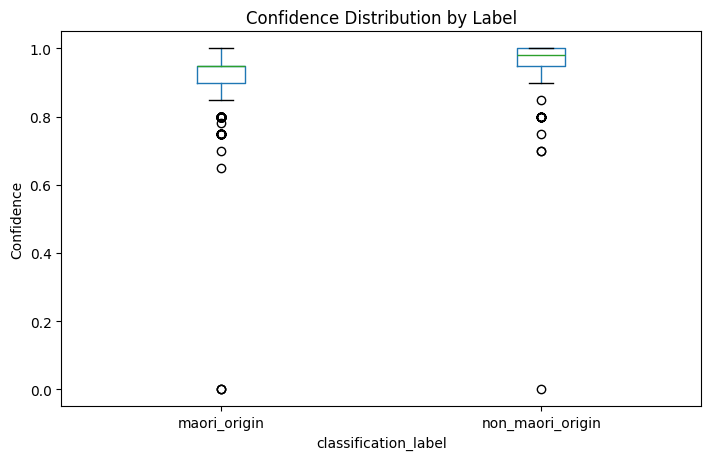

In [24]:
plot_confidence_boxplot(df_filtered)

### 3️⃣ Spot-check low confidence cases

In [25]:
low_conf_df = df_filtered.sort_values("classification_confidence").head(200)[
    [
        "classification_label",
        "classification_confidence",
        "HpsProceedingHeading",
        "HpsProceedingContent",
        "_filename"
    ]
]
low_conf_df.head(40)

,classification_label,classification_confidence,HpsProceedingHeading,HpsProceedingContent,_filename
5691,non_maori_origin,0.00,"Petitions, Papers, Select Committee Reports, a...",SPEAKER : Petitions have been delivered to the...,hansard_2021-07-01_body_section_3.json
3020,maori_origin,0.00,Debate on Prime Minister’s Statement,Debate resumed from 14 February.\n\nHon Dr JON...,hansard_2017-02-15_body_section_3.json
6720,maori_origin,0.00,Report of Committee of the Whole House,CHAIRPERSON (Hon Jenny Salesa) : Madam Speaker...,hansard_2022-11-15_body_section_14.json
5542,maori_origin,0.00,Questions to Ministers,Question No. 1—Prime Minister\n\n1. Hon JUDITH...,hansard_2021-05-12_body_section_3.json
2428,maori_origin,0.65,Debate on Budget Policy Statement,DAVID BENNETT (Chairperson of the Finance and ...,hansard_2016-03-09_body_section_4.json
3022,maori_origin,0.70,Fire and Emergency New Zealand Bill,Second Reading\n\nHon PETER DUNNE (Minister of...,hansard_2017-02-15_body_section_5.json
4864,non_maori_origin,0.70,Debate on Prime Minister’s Statement,Debate resumed from 12 February.\n\nHon KELVIN...,hansard_2020-02-13_body_section_3.json
2132,non_maori_origin,0.70,Questions to Ministers,Schools—Māori Boarding Schools\n\n1. MARAMA FO...,hansard_2015-08-20_body_section_2.json
2067,maori_origin,0.75,Social Security (Extension of Young Persons Se...,First Reading\n\nHon ANNE TOLLEY (Minister for...,hansard_2015-07-23_body_section_6.json
1360,maori_origin,0.75,Electoral Amendment Bill,Third Reading\n\nDebate resumed from 13 March....,hansard_2014-03-18_body_section_3.json


In [26]:
low_conf_df.to_parquet("low_conf.parquet")

In [27]:
inspect_file_size("low_conf.parquet")

5.64 MB


In [28]:
!cp "low_conf.parquet" "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/hansard_low_conf.parquet"

In [29]:
count_high_confidence = len(df_filtered[df_filtered["classification_confidence"] >= 0.9])
print(f"Number of rows with classification_confidence >= 0.9: {count_high_confidence}")

count_low_confidence = len(df_filtered[df_filtered["classification_confidence"] < 0.9])
print(f"Number of rows with classification_confidence < 0.9: {count_low_confidence}")

Number of rows with classification_confidence >= 0.9: 8776
Number of rows with classification_confidence < 0.9: 173


In [30]:
df_filtered_high = df_filtered[df_filtered["classification_confidence"] >= 0.9].copy()
df_filtered_high.reset_index(drop=True, inplace=True)
df_filtered_high.info()
print(f"Count of rows in df_filtered_high: {len(df_filtered_high)}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8776 entries, 0 to 8775
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   HpsProceedingHeading       8776 non-null   object 
 1   HpsProceedingContent       8776 non-null   object 
 2   classification_label       8776 non-null   object 
 3   classification_confidence  8776 non-null   float64
 4   classification_reason      8776 non-null   object 
 5   _filename                  8776 non-null   object 
 6   _path                      8776 non-null   object 
dtypes: float64(1), object(6)
memory usage: 480.1+ KB
Count of rows in df_filtered_high: 8776


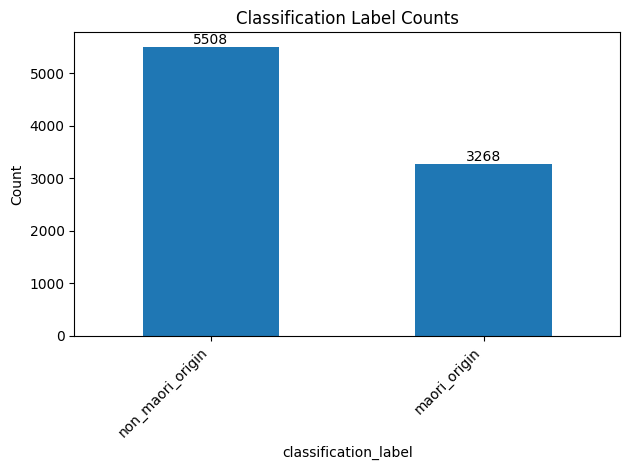

In [31]:
plot_label_counts(df_filtered_high)

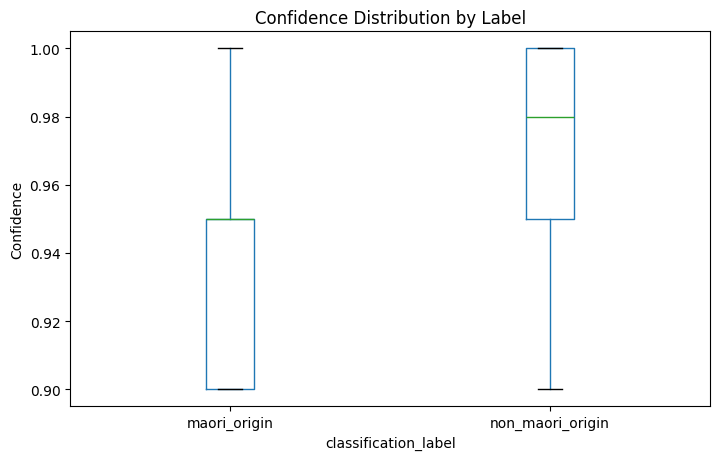

In [32]:
plot_confidence_boxplot(df_filtered_high)

### 4️⃣ Text length EDA

In [33]:
df_filtered_high["content_char_len"] = df_filtered_high["HpsProceedingContent"].str.len()
df_filtered_high["content_word_len"] = df_filtered_high["HpsProceedingContent"].str.split().str.len()


In [34]:
df_filtered_high.groupby("classification_label")[["content_word_len"]].describe()


content_word_len                                          \
                                count          mean          std  min     25%   
classification_label                                                            
maori_origin                   3268.0  10339.874847  9035.335366  9.0  5728.0   
non_maori_origin               5508.0   5013.157226  6562.111949  9.0   141.0   

                                                  
                         50%       75%       max  
classification_label                              
maori_origin          8958.0  11937.25  104673.0  
non_maori_origin      2092.5   8728.00   88048.0

<Axes: >

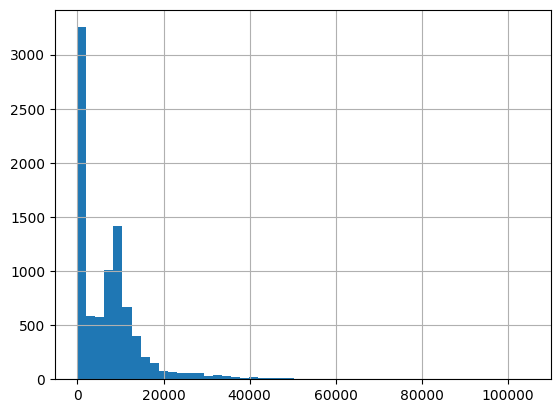

In [35]:
df_filtered_high["content_word_len"].hist(bins=50)


In [36]:
def plot_content_len_dist(input_df):
  for label in input_df["classification_label"].unique():
      input_df[input_df["classification_label"] == label]["content_word_len"].hist(
          bins=40, alpha=0.6, label=label
      )

  plt.legend()
  plt.title("Content Length Distribution by Label")
  plt.xlabel("Number of Words in Content")
  plt.ylabel("Frequency")

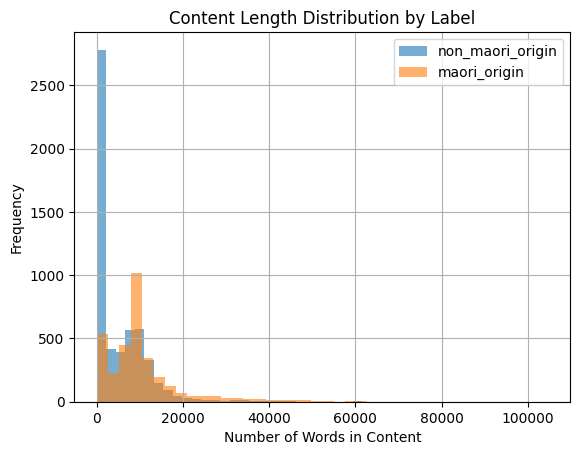

In [37]:
plot_content_len_dist(df_filtered_high)

In [38]:
df_filtered_high.groupby("classification_label")["content_word_len"].median()


,content_word_len
classification_label,
maori_origin,8958.0
non_maori_origin,2092.5


In [39]:
def trim_by_quantiles(input_df, col, label_col, q_low=0.1, q_high=0.9):
    keep_mask = []

    for label, g in input_df.groupby(label_col):
        low = g[col].quantile(q_low)
        high = g[col].quantile(q_high)
        keep_mask.append(
            g[(g[col] >= low) & (g[col] <= high)]
        )

    return pd.concat(keep_mask)


In [43]:
df_len_trimmed = trim_by_quantiles(
    df_filtered_high,
    col="content_word_len",
    label_col="classification_label",
    q_low=0.05,
    q_high=0.95
)
df_len_trimmed.reset_index(drop=True, inplace=True)
df_len_trimmed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7905 entries, 0 to 7904
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   HpsProceedingHeading       7905 non-null   object 
 1   HpsProceedingContent       7905 non-null   object 
 2   classification_label       7905 non-null   object 
 3   classification_confidence  7905 non-null   float64
 4   classification_reason      7905 non-null   object 
 5   _filename                  7905 non-null   object 
 6   _path                      7905 non-null   object 
 7   content_char_len           7905 non-null   int64  
 8   content_word_len           7905 non-null   int64  
dtypes: float64(1), int64(2), object(6)
memory usage: 555.9+ KB


In [44]:
def trim_by_min_word_count(input_df, min_words):
    return input_df[input_df["content_word_len"] >= min_words].copy()

In [52]:
df_min_word_trimmed = trim_by_min_word_count(df_filtered_high, min_words=500)
df_min_word_trimmed.reset_index(drop=True, inplace=True)
df_min_word_trimmed.info()
display(df_min_word_trimmed.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6226 entries, 0 to 6225
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   HpsProceedingHeading       6226 non-null   object 
 1   HpsProceedingContent       6226 non-null   object 
 2   classification_label       6226 non-null   object 
 3   classification_confidence  6226 non-null   float64
 4   classification_reason      6226 non-null   object 
 5   _filename                  6226 non-null   object 
 6   _path                      6226 non-null   object 
 7   content_char_len           6226 non-null   int64  
 8   content_word_len           6226 non-null   int64  
dtypes: float64(1), int64(2), object(6)
memory usage: 437.9+ KB


,HpsProceedingHeading,HpsProceedingContent,classification_label,classification_confidence,classification_reason,_filename,_path,content_char_len,content_word_len
0,Queen Elizabeth II—Diamond Jubilee,Rt Hon JOHN KEY (Prime Minister): I seek leave...,maori_origin,0.90,While the primary topic is the Queen's Diamond...,hansard_2012-02-07_body_section_3.json,/content/drive/MyDrive/NZ/University of Waikat...,12324,2163
1,Questions to Ministers,Economy—Government Priorities and Challenges\n...,maori_origin,0.95,The document contains multiple substantive dis...,hansard_2012-02-07_body_section_4.json,/content/drive/MyDrive/NZ/University of Waikat...,39296,6800
2,Address in Reply,Debate resumed from 21 December 2011.\n\nHon G...,maori_origin,0.90,The document contains substantive discussion o...,hansard_2012-02-07_body_section_5.json,/content/drive/MyDrive/NZ/University of Waikat...,109464,19276
3,National Animal Identification and Tracing Bill,In Committee\n\nHon DAVID CARTER (Minister for...,non_maori_origin,1.00,The document contains a substantive parliament...,hansard_2012-02-07_body_section_6.json,/content/drive/MyDrive/NZ/University of Waikat...,50978,9070
4,Road User Charges Bill,In Committee\n\nDebate resumed from 5 October ...,non_maori_origin,0.98,The document contains a substantive parliament...,hansard_2012-02-07_body_section_7.json,/content/drive/MyDrive/NZ/University of Waikat...,20583,3621


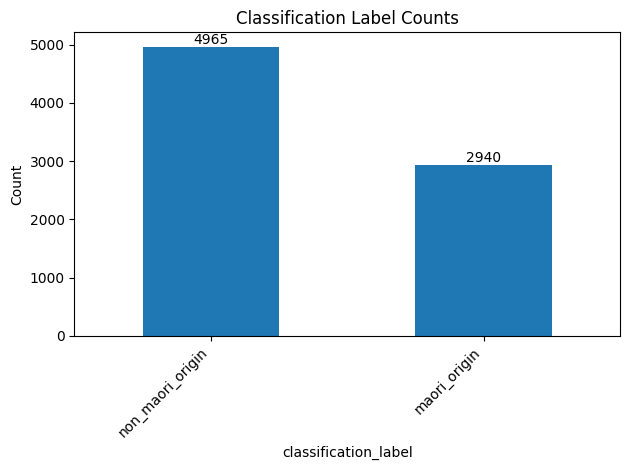

In [53]:
plot_label_counts(df_len_trimmed)

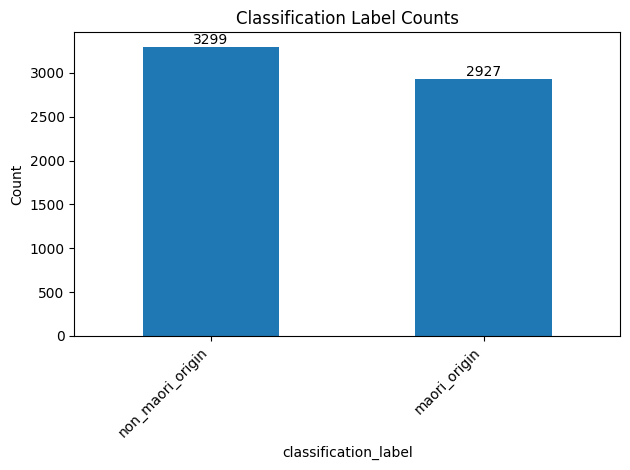

In [54]:
plot_label_counts(df_min_word_trimmed)

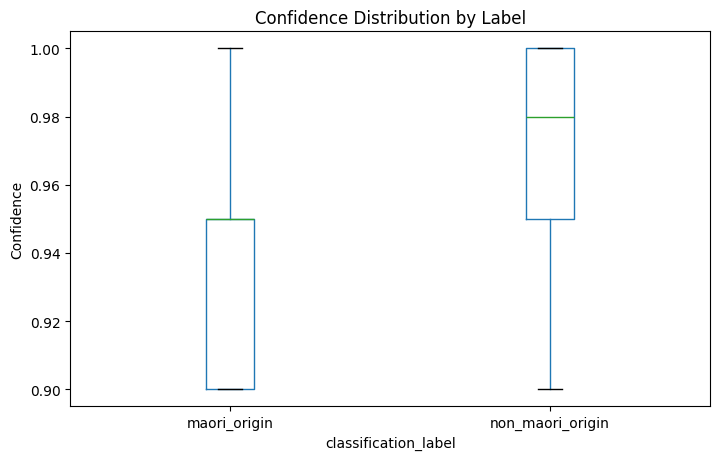

In [55]:
plot_confidence_boxplot(df_len_trimmed)

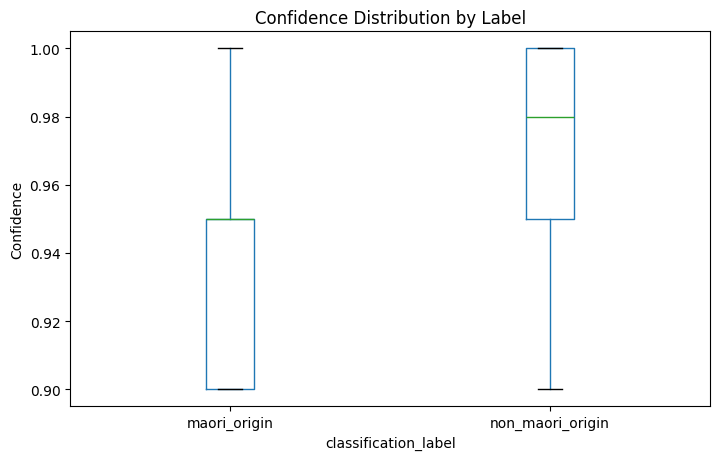

In [56]:
plot_confidence_boxplot(df_min_word_trimmed)

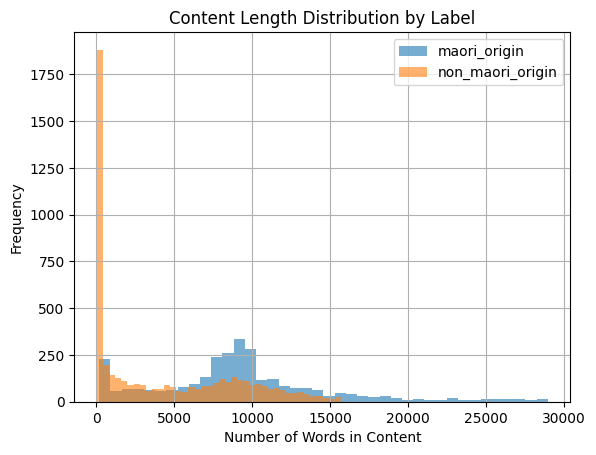

In [57]:
plot_content_len_dist(df_len_trimmed)

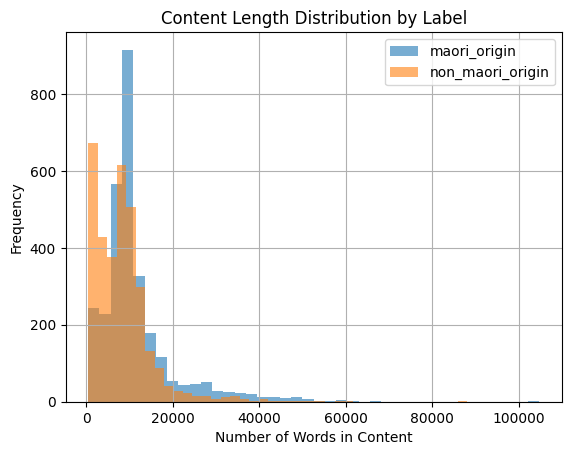

In [58]:
plot_content_len_dist(df_min_word_trimmed)

### 5️⃣ Summary

In [59]:
def print_summary(input_df):
    summary = (
        input_df
        .groupby("classification_label")
        .agg(
            docs=("classification_label", "count"),
            avg_conf=("classification_confidence", "mean"),
            min_conf=("classification_confidence", "min"),
            max_conf=("classification_confidence", "max"),
            median_words=("content_word_len", "median"),
            min_words=("content_word_len", "min"),
            max_words=("content_word_len", "max"),
        )
    )

    return summary

In [60]:
print_summary(df_len_trimmed)

,docs,avg_conf,min_conf,max_conf,median_words,min_words,max_words
classification_label,,,,,,,
maori_origin,2940,0.941969,0.9,1.0,8958.0,174,28951
non_maori_origin,4965,0.972139,0.9,1.0,2074.0,37,15686


In [61]:
print_summary(df_min_word_trimmed)

,docs,avg_conf,min_conf,max_conf,median_words,min_words,max_words
classification_label,,,,,,,
maori_origin,2927,0.942292,0.9,1.0,9373.0,501,104673
non_maori_origin,3299,0.973292,0.9,1.0,7792.0,500,88048


In [62]:
df_len_trimmed.to_parquet("df_len_trimmed.parquet")
df_min_word_trimmed.to_parquet("df_min_word_trimmed.parquet")

!cp "df_len_trimmed.parquet" "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/hansard_len_trimmed.parquet"
!cp "df_min_word_trimmed.parquet" "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/hansard_min_word_trimmed.parquet"

In [63]:
inspect_file_size("df_len_trimmed.parquet")

143.99 MB


In [64]:
inspect_file_size("df_min_word_trimmed.parquet")

180.34 MB


Chosing DF_MIN_WORD_TRIMMED as the final DF

In [67]:
df_min_word_trimmed["classification_label"].value_counts(normalize=True)


,proportion
classification_label,
non_maori_origin,0.529875
maori_origin,0.470125


In [68]:
df_min_word_trimmed["classification_label"].unique()


array(['maori_origin', 'non_maori_origin'], dtype=object)

In [58]:
label2id = {
    "maori_origin": 0,
    "non_maori_origin": 1,
}

id2label = {v: k for k, v in label2id.items()}

In [ ]:
df_min_word_trimmed["label"] = df_min_word_trimmed["classification_label"].map(label2id)


In [71]:
df_min_word_trimmed["label"].value_counts(normalize=True)


,proportion
label,
1,0.529875
0,0.470125


In [72]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df_min_word_trimmed,
    test_size=0.2,               # 80 / 20 split
    stratify=df_min_word_trimmed["label"],  # THIS is the key line
    random_state=42
)


In [73]:
print("Train distribution:")
print(train_df["classification_label"].value_counts(normalize=True))

print("\nTest distribution:")
print(test_df["classification_label"].value_counts(normalize=True))


Train distribution:
classification_label
non_maori_origin    0.52992
maori_origin        0.47008
Name: proportion, dtype: float64

Test distribution:
classification_label
non_maori_origin    0.529695
maori_origin        0.470305
Name: proportion, dtype: float64


In [74]:
from datasets import Dataset, DatasetDict

train_ds = Dataset.from_pandas(
    train_df,
    preserve_index=False
)

test_ds = Dataset.from_pandas(
    test_df,
    preserve_index=False
)

hf_dataset = DatasetDict({
    "train": train_ds,
    "test": test_ds,
})


In [76]:
import datasets

hf_dataset = hf_dataset.cast_column(
    "label",
    datasets.ClassLabel(
        num_classes=2,
        names=["maori_origin", "non_maori_origin"]
    )
)


Casting the dataset:   0%|          | 0/4980 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/1246 [00:00<?, ? examples/s]

In [77]:
hf_dataset
hf_dataset["train"].features


{'HpsProceedingHeading': Value('string'),
 'HpsProceedingContent': Value('string'),
 'classification_label': Value('string'),
 'classification_confidence': Value('float64'),
 'classification_reason': Value('string'),
 '_filename': Value('string'),
 '_path': Value('string'),
 'content_char_len': Value('int64'),
 'content_word_len': Value('int64'),
 'label': ClassLabel(names=['maori_origin', 'non_maori_origin'])}

In [78]:
hf_dataset["train"][0]


{'HpsProceedingHeading': 'Questions to Ministers',
 'HpsProceedingContent': 'Government—Relationship with Support Partners\n\n1. Hon DAVID CUNLIFFE (Leader of the Opposition) to the Prime Minister: Does he have confidence in the stability of his Government?\n\nRt Hon JOHN KEY (Prime Minister): Yes.\n\nHon David Cunliffe : Will he depend on Mr Banks’ vote to pass legislation for the remainder of this term?\n\nRt Hon JOHN KEY : That will depend, obviously, on whether it is either a confidence and supply issue or case by case, as we deal with every party in Parliament. But, in principle, yes, where Mr Banks chooses to exercise that vote on behalf of the ACT Party.\n\nHon David Cunliffe : If it is on a case by case basis, as the Prime Minister has said, what does it say that he could not muster a majority for his copper tax or the Resource Management Act changes, and how can the country be confident of stable Government over the next year?\n\nRt Hon JOHN KEY : The fact that we have not int

In [79]:
hf_dataset.save_to_disk("/content/hansard_final_hf_dataset")

Saving the dataset (0/1 shards):   0%|          | 0/4980 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1246 [00:00<?, ? examples/s]

In [82]:
!cp -r "/content/hansard_final_hf_dataset" "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/"

In [5]:
import datasets

hf_dataset = datasets.load_from_disk("/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/hansard_final_hf_dataset")

In [6]:
hf_dataset

DatasetDict({
    train: Dataset({
        features: ['HpsProceedingHeading', 'HpsProceedingContent', 'classification_label', 'classification_confidence', 'classification_reason', '_filename', '_path', 'content_char_len', 'content_word_len', 'label'],
        num_rows: 4980
    })
    test: Dataset({
        features: ['HpsProceedingHeading', 'HpsProceedingContent', 'classification_label', 'classification_confidence', 'classification_reason', '_filename', '_path', 'content_char_len', 'content_word_len', 'label'],
        num_rows: 1246
    })
})

In [7]:
!pip install huggingface_hub -q

In [42]:
from huggingface_hub import notebook_login
from google.colab import userdata

# Retrieve the token from Colab Secrets
hf_token = userdata.get('HF_TOKEN')

# Log in programmatically
notebook_login()

In [10]:
dataset_repo_name = "dinushiTJ/nz_hansard_classification"
hf_dataset.push_to_hub(dataset_repo_name)

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/5 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :   4%|4         | 6.82MB /  153MB            

...

Creating parquet from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  10%|9         | 3.67MB / 36.8MB            

CommitInfo(commit_url='https://huggingface.co/datasets/dinushiTJ/nz_hansard_classification/commit/b152d0c0754cc76840cac964cd3f7f6279e3805a', commit_message='Upload dataset', commit_description='', oid='b152d0c0754cc76840cac964cd3f7f6279e3805a', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/dinushiTJ/nz_hansard_classification', endpoint='https://huggingface.co', repo_type='dataset', repo_id='dinushiTJ/nz_hansard_classification'), pr_revision=None, pr_num=None)

First, we need to install the `transformers` library to use pre-trained tokenizers.

In [ ]:
!pip install transformers -q

In [11]:
from transformers import AutoTokenizer

# Load the Gemma tokenizer
tokenizer = AutoTokenizer.from_pretrained("google/gemma-3-4b-it")

def tokenize_function(examples):
    return {"token_count": [len(t) for t in tokenizer(examples["HpsProceedingContent"])["input_ids"]]}


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

In [12]:
hf_dataset = hf_dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/4980 [00:00<?, ? examples/s]

Map:   0%|          | 0/1246 [00:00<?, ? examples/s]

In [13]:
print(hf_dataset)
print(hf_dataset["train"].features)
print(hf_dataset["train"][0])

DatasetDict({
    train: Dataset({
        features: ['HpsProceedingHeading', 'HpsProceedingContent', 'classification_label', 'classification_confidence', 'classification_reason', '_filename', '_path', 'content_char_len', 'content_word_len', 'label', 'token_count'],
        num_rows: 4980
    })
    test: Dataset({
        features: ['HpsProceedingHeading', 'HpsProceedingContent', 'classification_label', 'classification_confidence', 'classification_reason', '_filename', '_path', 'content_char_len', 'content_word_len', 'label', 'token_count'],
        num_rows: 1246
    })
})
{'HpsProceedingHeading': Value('string'), 'HpsProceedingContent': Value('string'), 'classification_label': Value('string'), 'classification_confidence': Value('float64'), 'classification_reason': Value('string'), '_filename': Value('string'), '_path': Value('string'), 'content_char_len': Value('int64'), 'content_word_len': Value('int64'), 'label': ClassLabel(names=['maori_origin', 'non_maori_origin']), 'token_count

In [14]:
print("Overall token count statistics:")
print(hf_dataset["train"].to_pandas()["token_count"].describe())

print("\nToken count statistics by classification_label:")
print(hf_dataset["train"].to_pandas().groupby("classification_label")["token_count"].describe())

Overall token count statistics:
count      4980.000000
mean      12339.180924
std       10160.953592
min         575.000000
25%        6493.250000
50%       10917.000000
75%       14255.250000
max      128641.000000
Name: token_count, dtype: float64

Token count statistics by classification_label:
                       count          mean           std    min     25%  \
classification_label                                                      
maori_origin          2341.0  14718.343016  11327.378377  684.0  9425.0   
non_maori_origin      2639.0  10228.677529   8460.020350  575.0  4209.0   

                          50%      75%       max  
classification_label                              
maori_origin          11790.0  16212.0  128641.0  
non_maori_origin       9664.0  13180.5  114140.0  


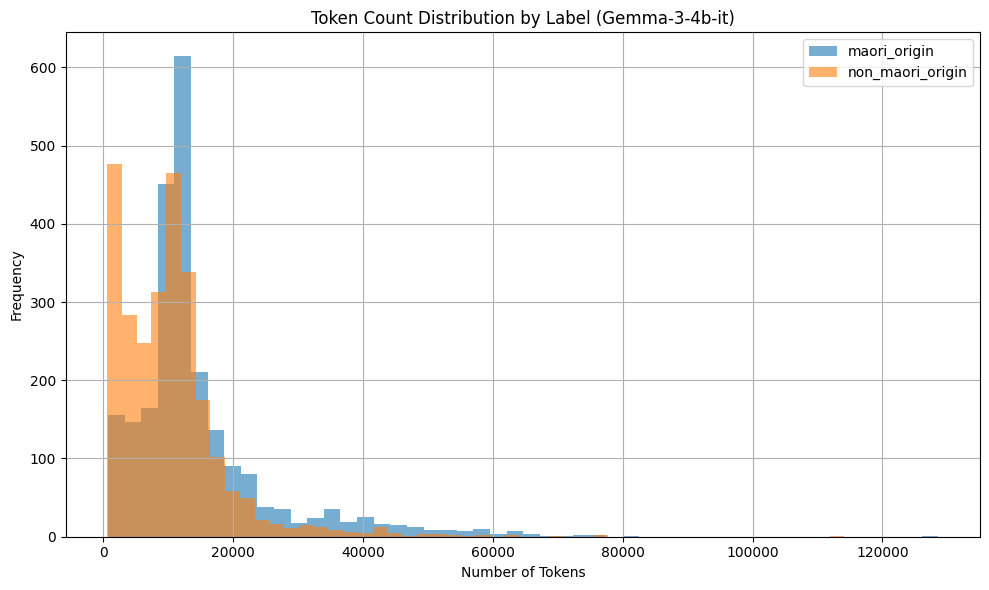

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
for label in hf_dataset["train"].unique("classification_label"):
    hf_dataset["train"].to_pandas()[hf_dataset["train"].to_pandas()["classification_label"] == label]["token_count"].hist(
        bins=50, alpha=0.6, label=label
    )

plt.legend()
plt.title("Token Count Distribution by Label (Gemma-3-4b-it)")
plt.xlabel("Number of Tokens")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [16]:
dataset_repo_name = "dinushiTJ/nz_hansard_classification"
hf_dataset.push_to_hub(dataset_repo_name)

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/5 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  16%|#6        | 25.1MB /  153MB            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  91%|######### | 33.4MB / 36.8MB            

README.md:   0%|          | 0.00/880 [00:00<?, ?B/s]

CommitInfo(commit_url='https://huggingface.co/datasets/dinushiTJ/nz_hansard_classification/commit/1d693e96a735d339be05476449cb82a0648aca06', commit_message='Upload dataset', commit_description='', oid='1d693e96a735d339be05476449cb82a0648aca06', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/dinushiTJ/nz_hansard_classification', endpoint='https://huggingface.co', repo_type='dataset', repo_id='dinushiTJ/nz_hansard_classification'), pr_revision=None, pr_num=None)

In [26]:
from datasets import load_dataset

dataset_repo_name = "dinushiTJ/nz_hansard_classification"
hf_dataset = load_dataset(dataset_repo_name)

In [27]:
def prep_user_prompt(doc: str):
    return f'''You are a specialist in classifying New Zealand Parliament Hansard records.

    TASK: Classify the document section below into EXACTLY ONE category.

    CATEGORIES:
    - maori_origin: Substantive discussion of Māori-related topics
    - non_maori_origin: Parliamentary content not primarily about Māori topics

    CLASSIFICATION RULES:

    1. maori_origin - Use ONLY when the document substantively discusses:
      • Māori people, communities, or populations
      • Māori culture, language (te reo Māori), traditions, or identity
      • Māori political, legal, social, or historical matters
      • Treaty of Waitangi, Māori land rights, iwi/hapū governance
      • Māori-specific policies, programs, or legislation

      CRITICAL: Mere mentions do NOT qualify:
      • Māori names of people or places
      • Incidental references to Māori individuals
      • Geographic locations with Māori names
      • Brief acknowledgments or greetings

      The content must be ABOUT Māori topics, not just mention them.

    2. non_maori_origin - Use for:
      • Parliamentary debates, speeches, questions, or discussions on other topics
      • Legislation or policy not primarily focused on Māori matters
      • General government business where Māori relevance is absent or incidental

    IMPORTANT GUIDELINES:
    - If Māori relevance is ambiguous or peripheral → classify as non_maori_origin
    - If you are uncertain between maori_origin and non_maori_origin → choose non_maori_origin
    - Base decisions solely on the content provided
    - Confidence should reflect how clear-cut the classification is (0.0-1.0)

    OUTPUT FORMAT (return ONLY this JSON, no other text):
    {{
      "label": "maori_origin | non_maori_origin",
      "confidence": 0.85,
      "reason": "Brief explanation of why this classification was chosen."
    }}

    DOCUMENT SECTION:
    """
    {doc}
    """
    '''

In [28]:
import json

def prep_model_response(label: str, confidence: float, reason: str):
    return json.dumps({
        "label": label,
        "confidence": confidence,
        "reason": reason
    })

In [29]:
def create_conversations(example):
    user_prompt = prep_user_prompt(example["HpsProceedingContent"])
    model_response = prep_model_response(
        example["classification_label"],
        example["classification_confidence"],
        example["classification_reason"]
    )

    conversations_list = [
        {"content": user_prompt, "role": "user"},
        {"content": model_response, "role": "model"}
    ]
    return {"conversations": conversations_list}

Now, let's apply this function to your `hf_dataset` to create the new `conversations` column.

In [30]:
hf_dataset = hf_dataset.map(create_conversations)

Map:   0%|          | 0/4980 [00:00<?, ? examples/s]

Map:   0%|          | 0/1246 [00:00<?, ? examples/s]

Let's inspect the updated dataset structure and a sample entry to verify the new column.

In [39]:
print(hf_dataset)
print(hf_dataset["train"].features)
conv = hf_dataset["train"][0]["conversations"]
print(json.dumps({"conv": conv}, indent=2))

DatasetDict({
    train: Dataset({
        features: ['HpsProceedingHeading', 'HpsProceedingContent', 'classification_label', 'classification_confidence', 'classification_reason', '_filename', '_path', 'content_char_len', 'content_word_len', 'label', 'token_count', 'conversations'],
        num_rows: 4980
    })
    test: Dataset({
        features: ['HpsProceedingHeading', 'HpsProceedingContent', 'classification_label', 'classification_confidence', 'classification_reason', '_filename', '_path', 'content_char_len', 'content_word_len', 'label', 'token_count', 'conversations'],
        num_rows: 1246
    })
})
{'HpsProceedingHeading': Value('string'), 'HpsProceedingContent': Value('string'), 'classification_label': Value('string'), 'classification_confidence': Value('float64'), 'classification_reason': Value('string'), '_filename': Value('string'), '_path': Value('string'), 'content_char_len': Value('int64'), 'content_word_len': Value('int64'), 'label': ClassLabel(names=['maori_origin', 

In [40]:
hf_dataset.push_to_hub(dataset_repo_name)

Uploading the dataset shards:   0%|          | 0/2 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/3 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  16%|#6        | 25.1MB /  154MB            

...

Creating parquet from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  40%|###9      | 29.5MB / 74.7MB            

CommitInfo(commit_url='https://huggingface.co/datasets/dinushiTJ/nz_hansard_classification/commit/00ff2a513c91c9d4cae008b9572788458dc242dd', commit_message='Upload dataset', commit_description='', oid='00ff2a513c91c9d4cae008b9572788458dc242dd', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/dinushiTJ/nz_hansard_classification', endpoint='https://huggingface.co', repo_type='dataset', repo_id='dinushiTJ/nz_hansard_classification'), pr_revision=None, pr_num=None)

## Analyze token counts

In [62]:
from datasets import load_dataset

dataset_repo_name = "dinushiTJ/nz_hansard_classification"
hf_dataset = load_dataset(dataset_repo_name)

In [63]:
import pandas as pd

train_df_combined = hf_dataset["train"].to_pandas()
test_df_combined = hf_dataset["test"].to_pandas()

combined_df = pd.concat([train_df_combined, test_df_combined]).reset_index(drop=True)
print(combined_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6226 entries, 0 to 6225
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   HpsProceedingHeading       6226 non-null   object 
 1   HpsProceedingContent       6226 non-null   object 
 2   classification_label       6226 non-null   object 
 3   classification_confidence  6226 non-null   float64
 4   classification_reason      6226 non-null   object 
 5   _filename                  6226 non-null   object 
 6   _path                      6226 non-null   object 
 7   content_char_len           6226 non-null   int64  
 8   content_word_len           6226 non-null   int64  
 9   label                      6226 non-null   int64  
 10  token_count                6226 non-null   int64  
 11  conversations              6226 non-null   object 
dtypes: float64(1), int64(4), object(7)
memory usage: 583.8+ KB
None


**Reasoning**:
To analyze the token count distribution for each classification label, I will now display descriptive statistics for the 'token_count' column, grouped by 'classification_label' from the newly created `combined_df`.



In [64]:
print("Token count statistics by classification_label for the combined dataset:")
print(combined_df.groupby("classification_label")["token_count"].describe())

Token count statistics by classification_label for the combined dataset:
                       count          mean           std    min     25%  \
classification_label                                                      
maori_origin          2927.0  14584.946361  11083.060786  684.0  9425.0   
non_maori_origin      3299.0  10173.032131   8326.625342  575.0  4208.5   

                          50%      75%       max  
classification_label                              
maori_origin          11795.0  16048.5  128641.0  
non_maori_origin       9630.0  13183.0  114140.0  


## Filter by Token Count

### Subtask:
Filter the combined DataFrame to include only data points where the 'token_count' is less than 20,000.


**Reasoning**:
Filter the `combined_df` to include only data points where `token_count` is less than 20,000 and store it in `filtered_df`.



In [65]:

max_token_count = 4096
filtered_df = combined_df[combined_df["token_count"] < max_token_count].copy()
print(f"Original combined_df shape: {combined_df.shape}")
print(f"Filtered_df shape: {filtered_df.shape}")
filtered_df.info()

Original combined_df shape: (6226, 12)
Filtered_df shape: (1064, 12)
<class 'pandas.core.frame.DataFrame'>
Index: 1064 entries, 9 to 6224
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   HpsProceedingHeading       1064 non-null   object 
 1   HpsProceedingContent       1064 non-null   object 
 2   classification_label       1064 non-null   object 
 3   classification_confidence  1064 non-null   float64
 4   classification_reason      1064 non-null   object 
 5   _filename                  1064 non-null   object 
 6   _path                      1064 non-null   object 
 7   content_char_len           1064 non-null   int64  
 8   content_word_len           1064 non-null   int64  
 9   label                      1064 non-null   int64  
 10  token_count                1064 non-null   int64  
 11  conversations              1064 non-null   object 
dtypes: float64(1), int64(4), object(7)
memor

**Reasoning**:
To analyze the token count distribution for each classification label after filtering, I will display descriptive statistics for the 'token_count' column, grouped by 'classification_label' from the `filtered_df`.



In [66]:
print("Token count statistics by classification_label for the filtered dataset:")
print(filtered_df.groupby("classification_label")["token_count"].describe())

Token count statistics by classification_label for the filtered dataset:
                      count         mean          std    min     25%     50%  \
classification_label                                                           
maori_origin          253.0  2334.300395  1026.394717  684.0  1426.0  2398.0   
non_maori_origin      811.0  2096.368681  1004.611303  575.0  1204.5  1948.0   

                         75%     max  
classification_label                  
maori_origin          3255.0  4087.0  
non_maori_origin      2969.0  4086.0  


**Reasoning**:
To visualize the token count distribution for each classification label after filtering, I will create a histogram using the `filtered_df`.



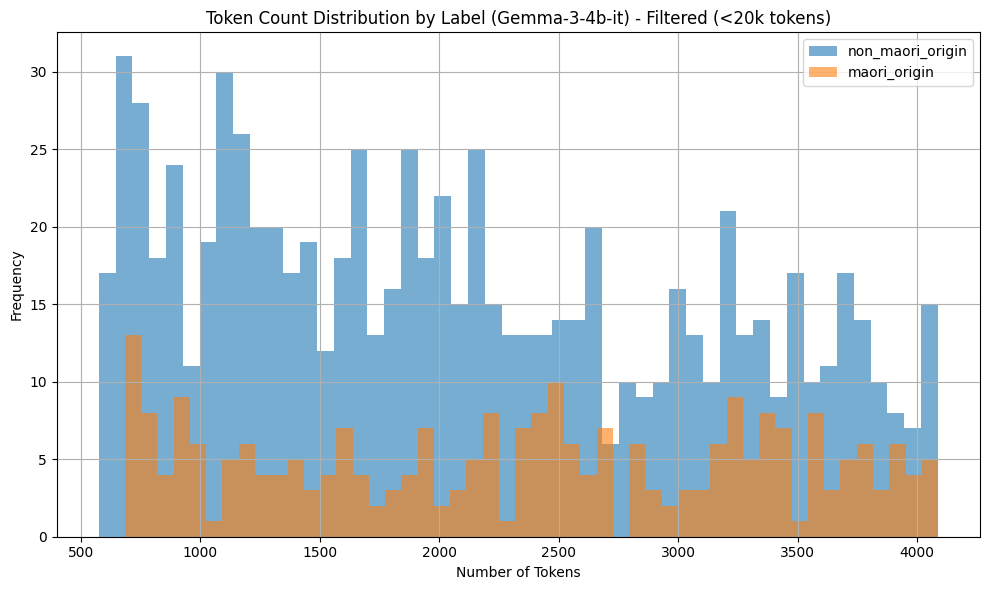

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
for label in filtered_df["classification_label"].unique():
    filtered_df[filtered_df["classification_label"] == label]["token_count"].hist(
        bins=50, alpha=0.6, label=label
    )

plt.legend()
plt.title("Token Count Distribution by Label (Gemma-3-4b-it) - Filtered (<20k tokens)")
plt.xlabel("Number of Tokens")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**Reasoning**:
The subtask of filtering the combined DataFrame based on token count and analyzing its distribution is complete. I have filtered the data and visualized the token count distribution. Now, I will save the filtered dataframe.



In [71]:
filtered_df.to_parquet(f"filtered_token_count_dataset_{max_token_count}.parquet")
!cp "filtered_token_count_dataset_{max_token_count}.parquet" "/content/drive/MyDrive/NZ/University of Waikato/Māori Data Findability Project/downloaded/hansard_filtered_token_count_{max_token_count}.parquet"

## Count Filtered Data Points

### Subtask:
Print the total number of data points remaining after filtering by token count.


**Reasoning**:
To fulfill the subtask, I need to get the total number of data points (rows) in the `filtered_df` and print it with a descriptive message.



In [75]:
print(f"Total number of data points remaining after filtering: {filtered_df.shape[0]}")

Total number of data points remaining after filtering: 2611


## Stratified Re-splitting

### Subtask:
Perform a new stratified train-test split on the filtered dataset, using the 'label' column for stratification. Use an 80/20 split (test_size=0.2).


**Reasoning**:
To perform a new stratified train-test split, I need to first import the `train_test_split` function from `sklearn.model_selection` and then load the `filtered_token_count_dataset.parquet` file into a DataFrame. This will allow me to access the necessary data for splitting.



In [76]:
from sklearn.model_selection import train_test_split
import pandas as pd

filtered_df = pd.read_parquet(f"filtered_token_count_dataset_{max_token_count}.parquet")
print(f"Loaded filtered_df with shape: {filtered_df.shape}")

Loaded filtered_df with shape: (1064, 12)


**Reasoning**:
Now that the filtered DataFrame is loaded, I will perform a stratified train-test split using the 'label' column to ensure proportional representation of each class in both the training and testing sets, as specified in the subtask.



In [78]:
train_df_new, test_df_new = train_test_split(
    filtered_df,
    test_size=0.2,
    stratify=filtered_df["label"],
    random_state=42
)

print(f"New training set shape: {train_df_new.shape}")
print(f"New testing set shape: {test_df_new.shape}")

print("\nNew Train distribution:")
print(train_df_new["classification_label"].value_counts(normalize=True))
print(train_df_new["classification_label"].value_counts(normalize=False))

print("\nNew Test distribution:")
print(test_df_new["classification_label"].value_counts(normalize=True))
print(test_df_new["classification_label"].value_counts(normalize=False))

New training set shape: (851, 12)
New testing set shape: (213, 12)

New Train distribution:
classification_label
non_maori_origin    0.762632
maori_origin        0.237368
Name: proportion, dtype: float64
classification_label
non_maori_origin    649
maori_origin        202
Name: count, dtype: int64

New Test distribution:
classification_label
non_maori_origin    0.760563
maori_origin        0.239437
Name: proportion, dtype: float64
classification_label
non_maori_origin    162
maori_origin         51
Name: count, dtype: int64


First, let's convert the `train_df_new` and `test_df_new` back into Hugging Face `Dataset` objects and then into a `DatasetDict`.

In [79]:
from datasets import Dataset, DatasetDict, ClassLabel

# Convert new train and test DataFrames to Hugging Face Dataset objects
new_train_ds = Dataset.from_pandas(train_df_new, preserve_index=False)
new_test_ds = Dataset.from_pandas(test_df_new, preserve_index=False)

# Create a new DatasetDict
new_hf_dataset = DatasetDict({
    "train": new_train_ds,
    "test": new_test_ds,
})

# Re-cast the 'label' column to ClassLabel
new_hf_dataset = new_hf_dataset.cast_column(
    "label",
    ClassLabel(
        num_classes=2,
        names=list(id2label.values())
    )
)

print(new_hf_dataset)
print(new_hf_dataset["train"].features)

Casting the dataset:   0%|          | 0/851 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/213 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['HpsProceedingHeading', 'HpsProceedingContent', 'classification_label', 'classification_confidence', 'classification_reason', '_filename', '_path', 'content_char_len', 'content_word_len', 'label', 'token_count', 'conversations'],
        num_rows: 851
    })
    test: Dataset({
        features: ['HpsProceedingHeading', 'HpsProceedingContent', 'classification_label', 'classification_confidence', 'classification_reason', '_filename', '_path', 'content_char_len', 'content_word_len', 'label', 'token_count', 'conversations'],
        num_rows: 213
    })
})
{'HpsProceedingHeading': Value('string'), 'HpsProceedingContent': Value('string'), 'classification_label': Value('string'), 'classification_confidence': Value('float64'), 'classification_reason': Value('string'), '_filename': Value('string'), '_path': Value('string'), 'content_char_len': Value('int64'), 'content_word_len': Value('int64'), 'label': ClassLabel(names=['maori_origin', 'n

In [80]:
from huggingface_hub import notebook_login, HfApi

# Ensure you are logged in to Hugging Face
# (If you ran the previous login cell, you should already be authenticated)
notebook_login()

# Define a new dataset repository name to indicate it's the filtered version
# You might want to change 'dinushiTJ' to your Hugging Face username
new_dataset_repo_name = f"dinushiTJ/nz_hansard_classification_{max_token_count}_tokens"

# Push the new dataset to the Hugging Face Hub
new_hf_dataset.push_to_hub(new_dataset_repo_name)

print(f"New filtered dataset pushed to: https://huggingface.co/datasets/{new_dataset_repo_name}")

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  53%|#####2    | 5.25MB / 9.98MB            

...

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              : 100%|##########| 2.63MB / 2.63MB            

New filtered dataset pushed to: https://huggingface.co/datasets/dinushiTJ/nz_hansard_classification_4096_tokens


https://ai.google.dev/gemma/docs/embeddinggemma/fine-tuning-embeddinggemma-with-sentence-transformers